# 02 · Response Matrix: from snapshots to a coupled matrix

$$\begin{pmatrix}\Delta\mathbf x\\\Delta\mathbf y\end{pmatrix}=\begin{pmatrix}R_{xx}&R_{xy}\\R_{yx}&R_{yy}\end{pmatrix}\begin{pmatrix}\Delta\mathbf c_H\\\Delta\mathbf c_V\end{pmatrix}$$

The first index is the measured plane, the second the corrector plane. $R_{xy}$ and $R_{yx}$ describe coupling.

## How the application computes it

1. finds every pair `DATA_<tag>_p<n>.pkl` / `DATA_<tag>_m<n>.pkl` in the directory;
2. keeps correctors upstream of the last selected BPM and BPMs downstream of the first corrector;
3. skips a pair when the readback changed by less than half of the requested change (an unexecuted kick);
4. adds the `BBA_*.pkl` states that previous BBA corrections copied into the directory, each session with its own orbit offset;
5. stacks every snapshot $k$ as a row and solves jointly, by least squares,
$$\mathbf b_k^T=\mathbf c_{H,k}^T R_{\cdot H}^T+\mathbf c_{V,k}^T R_{\cdot V}^T+\mathbf b_{0,g(k)}^T ,$$
6. with **Force triangular matrix**, sets the response of BPMs upstream of each corrector to exactly zero.


**Run:** follow [the setup guide](README.md), select the **Flight tutorials** kernel, then **Restart Kernel and Run All Cells**.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from tempfile import TemporaryDirectory
from tutorial_support import Beamline, acquire_pairs, reconstruct_response, response_block

machine = Beamline(seed=12)
with TemporaryDirectory(prefix='flight-response-') as directory:
    acquire_pairs(machine, directory, kick=0.15, cycles=2)
    response = reconstruct_response(machine, directory)
R = response_block(response)
print('Matrix shape (x and y BPMs, H and V correctors):', R.shape)
print(f'Relative error against the model: {np.linalg.norm(R - machine.R) / np.linalg.norm(machine.R):.3%}')

Matrix shape (x and y BPMs, H and V correctors): (10, 6)
Relative error against the model: 0.052%


## Can the matrix be inverted? Singular values

Orbit Bump and BBA solve $R\,\Delta\mathbf c=\Delta\mathbf b$. With the singular value decomposition $R=U\Sigma V^T$,
$$\Delta\mathbf c=R^+\Delta\mathbf b=\sum_i \frac{\mathbf u_i^T\Delta\mathbf b}{\sigma_i}\,\mathbf v_i .$$
Each orbit pattern $\mathbf u_i$ is corrected with the corrector pattern $\mathbf v_i$, amplified by $1/\sigma_i$. Noise in $\Delta\mathbf b$ is amplified the same way, so a very small $\sigma_i$ produces large, noisy kicks.

**PINV tolerance** (`rcond`, default $10^{-3}$) discards every mode with $\sigma_i<\mathrm{rcond}\cdot\sigma_{max}$. Choose it at the drop in the singular-value plot (**Plot Singular Values** in the GUI): keep the modes clearly above the noise, remove the ones below it.

The condition number $\kappa$ is the ratio of the largest to the smallest singular value. For example, $\kappa=22$ means that one combination of corrector changes produces an orbit displacement 22 times larger than the weakest combination, for equally sized changes.

The response to the weakest combination may be difficult to distinguish from measurement noise, making the computed correction less stable.

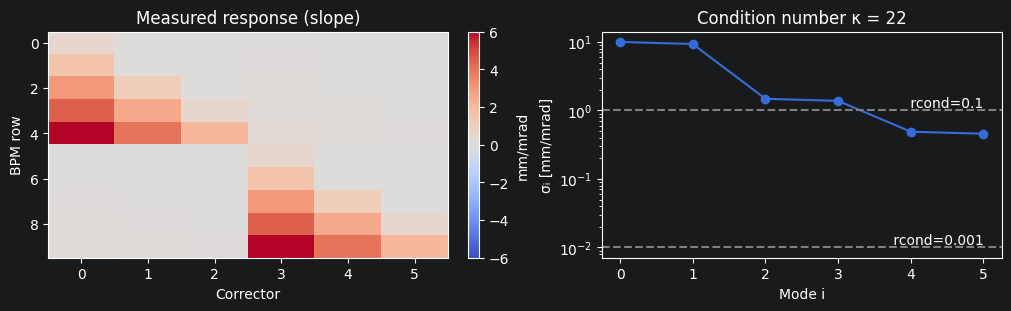

In [2]:
sv = np.linalg.svd(R, compute_uv=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
image = axes[0].imshow(R, aspect='auto', cmap='coolwarm', vmin=-np.abs(R).max(), vmax=np.abs(R).max())
axes[0].set(xlabel='Corrector', ylabel='BPM row', title='Measured response (slope)')
fig.colorbar(image, ax=axes[0], label='mm/mrad')
axes[1].semilogy(sv, 'o-', label='Singular values')
for rcond in (1e-1, 1e-3):
    axes[1].axhline(rcond * sv[0], ls='--', color='gray')
    axes[1].text(len(sv) - 1, rcond * sv[0], f' rcond={rcond:g}', va='bottom', ha='right')
axes[1].set(xlabel='Mode i', ylabel='σᵢ [mm/mrad]', title=f'Condition number κ = {sv[0] / sv[-1]:.0f}')
plt.show()

## Choosing the parameters

| GUI option | How to choose |
|---|---|
| Correctors, BPMs | Only devices that were measured. Correctors downstream of the last BPM and BPMs upstream of the first corrector are dropped automatically. |
| Force triangular matrix | On for transfer lines and linacs, where a corrector cannot move upstream BPMs, so noise there is set to zero. Off for rings: a closed orbit makes every corrector act on every BPM. |
| Second data directory | Changed-energy or changed-intensity SysID directory when you want to inspect $R_E-R_0$ or $R_Q-R_0$. |
| PINV tolerance (in Orbit Bump and BBA) | At the drop in singular values; $10^{-3}$ keeps $\kappa\le1000$. |
| Random excitation: N, σc | $N\gtrsim5\,(n_{correctors}+1)$; $\sigma_c$ as large as the orbit tolerance allows, since $u(R)\propto1/\sigma_c$. |